# Unit Search: Sparse Target Network

Can unit search find the structure of a deep, sparsely connected target network?

**Problem.** Each sample has $N = 1000$ standard normal inputs. The targets are the 100 outputs of a fixed target network
plus $N(0, 0.1^2)$ noise, so the best possible RMSE is 0.1 (dotted line in the plots). The target network has 3 hidden
layers of 20 LTUs. Each hidden unit reads 10 distinct units of lower depths (the inputs being depth 0), each picked by
choosing a lower depth uniformly and then a unit of that depth; each output does the same over the hidden depths only.
Weights are $N(0, 1)$, each hidden unit's threshold makes it fire 30% of the time, and each output is scaled to zero mean
and unit variance, so predicting 0 gives an RMSE of about 1. The target network is the same for every seed. A linear
fit on the inputs explains about 62% of the targets' variance.

**Learner.** Hidden units are LTUs (sigmoid derivative backward) at depths 1 to 3; a unit reads inputs and units of
lower depths, and the outputs (depth 4) read hidden units. The loss is half the summed squared error.
- **Network Autostep:** Autostep (`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.01,
  $\tau = 10^4$); hidden units standardized online, $h = (b - m)/\sqrt{\max(m(1 - m), 0.01)}$, with the backward pass
  through the statistics as in `unit_search/parallel_mnist_label_changes.ipynb`; hidden-unit weights start
  $U(-10^{-4}, 10^{-4})$, output weights and biases at 0.
- **SGD:** the same network with plain LTU bits (no standardization), LeCun uniform weights and biases at 0.

**Runs.** 300k steps, 5 seeds (1 per configuration in the unit search grid), every value averaged over each of 100 windows; final performance is the RMSE over the
last 10% of training.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS, N_OUTPUTS = 1000, 100
TEACHER_WIDTH = 20                   # target units per hidden layer, at depths 1-3
TEACHER_FAN_IN = 10                  # each target unit and output reads this many units of lower depths
FIRING_RATE = 0.3                    # each target hidden unit's threshold makes it fire this often
NOISE_STD = 0.1                      # observation noise on every target: the RMSE floor

# --- Network and learner ---
N_DEPTHS = 3                         # hidden depths; outputs are at depth N_DEPTHS + 1
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size, also the scale of initial hidden-unit weights
META_STEP_SIZE, TAU = 0.01, 1e4

# --- Training ---
N_SEEDS = 5
NUM_STEPS = 300_000
N_WINDOWS = 100                      # each window records the mean of every recorded value
RUNS_PER_BATCH = 5                   # runs vmapped together: a small batch's state stays in the GPU's cache
FINAL_FRACTION = 0.1                 # final performance: the last 10% of training

# --- Unit search ---
SEARCH_STEPS = 300_000               # steps of the unit search runs and their references
FAN_IN, FAN_OUT = 64, 10             # a new unit's random sources, and random hidden consumers below the last depth
UNIT_COST = FAN_IN + 1               # budget a new unit takes at its own depth
DEPTH_BUDGET = 512 * UNIT_COST       # 33,280: incoming connections and biases of each depth's units (512 new units)
SLOTS_PER_DEPTH = 640                # unit slots of each depth
HIDDEN_CAPACITY = 128                # connection slots of each hidden unit, besides the bias
BASE_PERIOD = 1000                   # steps between checks for a due structure change
PRUNE_EVERY = (3_000, 10_000, 30_000, 100_000)   # steps between structure changes
PRUNE_FRACTIONS = (0.03, 0.1, 0.3, 0.5)          # of each depth's units, pruned at each structure change
L1S = (0.001, 0.0)                   # L1 regularization of every weight (not biases), in Autostep's gradient

## Target network

In [3]:
def make_teacher(key, n_samples=20_000):
    # A sparse LTU network. Each hidden unit, at depth d, reads TEACHER_FAN_IN distinct units of lower depths, each
    # picked by choosing a lower depth uniformly (depth 0 being the inputs) and then a unit of that depth; each output
    # does the same over hidden depths only. Weights are N(0, 1), each hidden unit's threshold makes it fire
    # FIRING_RATE of the time, and each output is scaled to zero mean and unit variance. Units are stored by depth:
    # sources are [inputs, hidden units], hidden unit u of depth d being slot (d - 1) * TEACHER_WIDTH + u.
    n_hidden = N_DEPTHS * TEACHER_WIDTH
    depth = jnp.repeat(jnp.arange(1, N_DEPTHS + 1), TEACHER_WIDTH)
    source_depth = jnp.concatenate([jnp.zeros(N_INPUTS, int), depth])
    group_size = jnp.array([N_INPUTS] + [TEACHER_WIDTH] * N_DEPTHS)

    def pick(key, allowed):
        # TEACHER_FAN_IN distinct sources: a uniformly chosen allowed depth, then a uniformly chosen unit in it
        # (Gumbel top-k, which samples without replacement in proportion to these probabilities).
        p = jnp.where(allowed[source_depth], 1.0 / group_size[source_depth], 0.0)
        gumbel = jax.random.gumbel(key, p.shape)
        top = jax.lax.top_k(jnp.where(p > 0, jnp.log(p) + gumbel, -jnp.inf), TEACHER_FAN_IN)[1]
        return jnp.zeros(p.shape, bool).at[top].set(True)

    keys = jax.random.split(key, 4)
    lower = jnp.arange(N_DEPTHS + 1)[None, :] < depth[:, None]                    # (unit, depth) allowed sources
    hidden_mask = jax.vmap(pick)(jax.random.split(keys[0], n_hidden), lower)
    output_allowed = (jnp.arange(N_DEPTHS + 1) > 0)
    output_mask = jax.vmap(lambda k: pick(k, output_allowed))(jax.random.split(keys[1], N_OUTPUTS))[:, N_INPUTS:]
    hidden_w = jax.random.normal(keys[2], hidden_mask.shape) * hidden_mask
    output_w = jax.random.normal(keys[3], output_mask.shape) * output_mask

    # Thresholds, depth by depth, from a batch of inputs.
    x = jax.random.normal(jax.random.fold_in(key, 1), (n_samples, N_INPUTS))
    bits = jnp.zeros((n_samples, n_hidden))
    threshold = jnp.zeros(n_hidden)
    for d in range(1, N_DEPTHS + 1):
        z = jnp.concatenate([x, bits], axis=1) @ hidden_w.T
        threshold = jnp.where(depth == d, jnp.quantile(z, 1 - FIRING_RATE, axis=0), threshold)
        bits = jnp.where(depth == d, (z > threshold).astype(jnp.float32), bits)
    raw = bits @ output_w.T
    return {'hidden_w': hidden_w, 'threshold': threshold, 'depth': depth, 'output_w': output_w,
            'output_mean': raw.mean(0), 'output_std': raw.std(0)}


def teacher_targets(teacher, x):
    bits = jnp.zeros(N_DEPTHS * TEACHER_WIDTH)
    for d in range(1, N_DEPTHS + 1):
        z = teacher['hidden_w'] @ jnp.concatenate([x, bits])
        bits = jnp.where(teacher['depth'] == d, (z > teacher['threshold']).astype(jnp.float32), bits)
    return (teacher['output_w'] @ bits - teacher['output_mean']) / teacher['output_std']


TEACHER = make_teacher(jax.random.PRNGKey(123))


def next_sample(key):
    # One sample: standard normal inputs, and the target network's outputs plus N(0, NOISE_STD^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, teacher_targets(TEACHER, x) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped like the hidden units.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


def init_stats(shape):
    return Stats(jnp.full(shape, 0.5), jnp.zeros(shape), jnp.zeros(shape))


def hidden_values(bits, stats, autostep):
    # What a hidden unit sends: its standardized bit with network Autostep (statistics moved toward this sample
    # first), the bit itself with SGD. Returns the values and the moved firing rates.
    if not autostep:
        return bits, stats.hidden_mean
    mean = stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(bits) - stats.hidden_mean)
    return standardize(bits, mean, stats.error_mean, stats.error_h_mean), mean


def update(w, opt, stats, grads, sources, error, h, hidden_mean, autostep, step_size):
    # Network Autostep, or SGD at `step_size`, on the weights; the hidden units' statistics move toward this sample.
    # Returns the new weights, optimizer state and statistics.
    if not autostep:
        return jax.tree.map(lambda w, g: w - step_size * g, w, grads), opt, stats
    updates, opt = OPTIMIZER.update((grads, None, sources), opt, w)
    stats = Stats(hidden_mean, stats.error_mean + STAT_RATE * (error - stats.error_mean),
                  stats.error_h_mean + STAT_RATE * (error * h - stats.error_h_mean))
    return jax.tree.map(jnp.add, w, updates), opt, stats


def lecun(key, shape, fan_in):
    return jax.random.uniform(key, shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in)


# --- Fully connected networks: one weight matrix per layer, the last column the bias ---
LAYERS = [f'layer {d}' for d in range(1, N_DEPTHS + 1)] + ['output']


class Dense(NamedTuple):
    w: dict                     # LAYERS -> (units, units below + 1)
    opt: IDBDState
    stats: Stats                # each (N_DEPTHS, width)


def init_dense(key, width, autostep):
    # Network Autostep: hidden weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights 0, biases 0. SGD: LeCun
    # uniform weights, biases 0.
    shapes = [(width, N_INPUTS + 1)] + [(width, width + 1)] * (N_DEPTHS - 1) + [(N_OUTPUTS, width + 1)]
    keys = jax.random.split(key, len(LAYERS))
    if autostep:
        w = {k: jax.random.uniform(key, shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
             for k, key, shape in zip(LAYERS[:-1], keys, shapes)}
        w['output'] = jnp.zeros(shapes[-1])
    else:
        w = {k: lecun(key, shape, shape[1]) for k, key, shape in zip(LAYERS, keys, shapes)}
    w = {k: v.at[:, -1].set(0.0) for k, v in w.items()}
    return Dense(w, OPTIMIZER.init(w), init_stats((N_DEPTHS, width)))


def learn_dense(net, x, y, autostep, step_size):
    # One online update on half the summed squared error. Returns the new network and the mean squared error over the
    # outputs on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at each
    # hidden unit.
    def loss_fn(w, probe):
        a, sources, means, hs = x, {}, [], []
        for d, k in enumerate(LAYERS[:-1]):
            source = jnp.append(a, 1.0)
            sources[k] = jnp.broadcast_to(jax.lax.stop_gradient(source), w[k].shape)
            h, mean = hidden_values(ltu(w[k] @ source), jax.tree.map(lambda s: s[d], net.stats), autostep)
            a = h + probe[d]
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jnp.append(a, 1.0)
        sources['output'] = jnp.broadcast_to(jax.lax.stop_gradient(source), w['output'].shape)
        return 0.5 * jnp.sum((w['output'] @ source - y) ** 2), (sources, jnp.stack(hs), jnp.stack(means))

    probe = jnp.zeros(net.stats.hidden_mean.shape)
    (loss, (sources, h, hidden_mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, probe)
    w, opt, stats = update(net.w, net.opt, net.stats, grads, sources, error, h, hidden_mean, autostep, step_size)
    return Dense(w, opt, stats), 2 * loss / N_OUTPUTS


# --- Sparse networks: a block of unit slots per depth, each unit with a list of source slots ---
class Sparse(NamedTuple):
    # Hidden units sit in slots, a block of equal size per depth (depth 1 first); `alive` marks the slots that hold a
    # unit. Each hidden unit stores its connections as a list: slot k of unit u reads source src[u, k] with weight
    # w['hidden'][u, k], and the last column is the bias. A source is an input (index < N_INPUTS) or a hidden unit
    # (N_INPUTS + its slot); an empty connection slot points at an input (see `empty_sources`) that its mask zeroes.
    # The outputs' weights are a matrix over all the slots, `mask` saying which of their connections exist.
    w: dict                     # {'hidden': (slot, capacity + 1), 'output': (output, slot + 1)}
    mask: dict                  # which connections exist (biases of existing units included), shaped like w
    src: jax.Array              # (slot, capacity)
    alive: jax.Array            # (slot,)
    opt: IDBDState
    stats: Stats                # each (slot,)


def learn_sparse(net, x, y, feedback=None, l1=0.0):
    # One online network-Autostep update on half the summed squared error, with L1 regularization (its subgradient,
    # for every existing weight but the biases, added to the gradient Autostep learns from). Hidden units are computed
    # depth by depth, each pass computing only its depth's block. `feedback`, if given, replaces the output weights in
    # the backward pass only (shadow weights). Returns the new network and the mean squared error over the outputs on
    # this sample, before learning from it.
    n = len(net.alive)
    block = n // N_DEPTHS
    back = None if feedback is None else jax.lax.stop_gradient(feedback)

    def loss_fn(w, probe):
        w = {k: w[k] * net.mask[k] for k in w}
        a, gathered, bits = jnp.zeros(n), [], []
        for d in range(N_DEPTHS):
            rows = slice(d * block, (d + 1) * block)
            values = jnp.concatenate([x, a])[net.src[rows]]
            b = ltu(jnp.sum(w['hidden'][rows, :-1] * values, axis=1) + w['hidden'][rows, -1])
            h, _ = hidden_values(b, jax.tree.map(lambda s: s[rows], net.stats), True)
            a = a.at[rows].set(jnp.where(net.alive[rows], h + probe[rows], 0.0))
            gathered.append(jax.lax.stop_gradient(values))
            bits.append(jax.lax.stop_gradient(b))
        source = jnp.append(a, 1.0)
        if back is None:
            prediction = w['output'] @ source
        else:
            through_back = back[:, :-1] @ a
            prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                          - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(jnp.concatenate(gathered), jnp.ones((n, 1)), axis=1) * net.mask['hidden'],
                   'output': jnp.broadcast_to(jax.lax.stop_gradient(source), w['output'].shape) * net.mask['output']}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(a), jnp.concatenate(bits))

    probe = jnp.zeros(n)
    (loss, (sources, h, bits)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, probe)
    grads = {k: (grads[k] + l1 * jnp.sign(net.w[k]).at[:, -1].set(0.0)) * net.mask[k] for k in grads}
    hidden_mean = net.stats.hidden_mean + STAT_RATE * (bits - net.stats.hidden_mean)
    w, opt, stats = update(net.w, net.opt, net.stats, grads, sources, error, h, hidden_mean, True, None)
    return net._replace(w=w, opt=opt, stats=stats), 2 * loss / N_OUTPUTS


def empty_sources(n):
    # The sources that the empty connection slots of n units point at: inputs, spread over the slots so that the
    # backward pass's scatter-add into the sources does not pile onto one entry (which made each step twice as slow).
    return (jnp.arange(n * HIDDEN_CAPACITY) % N_INPUTS).reshape(n, HIDDEN_CAPACITY)


def init_sparse(key, src, mask, alive):
    # Hidden-unit weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights 0, biases 0.
    w_hidden = jax.random.uniform(key, mask['hidden'].shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
    w = {'hidden': w_hidden.at[:, -1].set(0.0) * mask['hidden'], 'output': jnp.zeros(mask['output'].shape)}
    return Sparse(w, mask, src, alive, OPTIMIZER.init(w), init_stats(len(alive)))

## Fixed connectivity: how performance scales with width

Fully connected networks with 3 hidden layers of 10 to 160 units, each layer reading only the one below, trained by
network Autostep and by SGD at several step sizes.

In [5]:
def train_dense(net, key, autostep, step_size, num_steps):
    # num_steps online steps in N_WINDOWS windows; records each window's mean squared error.
    def one_step(net, key):
        return learn_dense(net, *next_sample(key), autostep, step_size)

    def window(net, key):
        net, mse = jax.lax.scan(one_step, net, jax.random.split(key, num_steps // N_WINDOWS))
        return net, mse.mean()

    return jax.lax.scan(window, net, jax.random.split(key, N_WINDOWS))[1]


def run_dense(width, autostep, step_sizes, num_steps):
    # A fully connected network of `width` units per layer, at every step size on every seed, vmapped. Seed s gives
    # every run the same initial weights and samples. Returns the windows' RMSE, shaped (step size, seed, window).
    keys = lambda seed: jnp.tile(jax.random.split(jax.random.PRNGKey(seed), N_SEEDS), (len(step_sizes), 1))
    sizes = jnp.repeat(jnp.array(step_sizes, jnp.float32), N_SEEDS)
    nets = jax.vmap(lambda k: init_dense(k, width, autostep))(keys(0))
    started = perf_counter()
    mse = jax.jit(jax.vmap(lambda net, k, s: train_dense(net, k, autostep, s, num_steps)))(nets, keys(1), sizes)
    print(f'{len(step_sizes) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
    return np.sqrt(np.asarray(mse).reshape(len(step_sizes), N_SEEDS, N_WINDOWS))

In [6]:
WIDTHS = (10, 20, 40, 80, 160)
SGD_STEP_SIZES = (2 ** -10, 2 ** -8)
scaling = {}
for width in WIDTHS:
    scaling[width, 'network Autostep'] = run_dense(width, True, [0.0], NUM_STEPS)[0]
    for step_size, rmse in zip(SGD_STEP_SIZES, run_dense(width, False, SGD_STEP_SIZES, NUM_STEPS)):
        scaling[width, f'SGD, step size 2^{np.log2(step_size):.0f}'] = rmse

2026-10-29 21:52:24.699026: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 21:52:24.699075: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


5 runs in 17s


2026-10-29 21:52:43.084585: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 21:52:43.084633: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


10 runs in 11s


5 runs in 14s


10 runs in 11s


... (2 outputs left out)

5 runs in 18s


10 runs in 11s


5 runs in 21s


10 runs in 14s


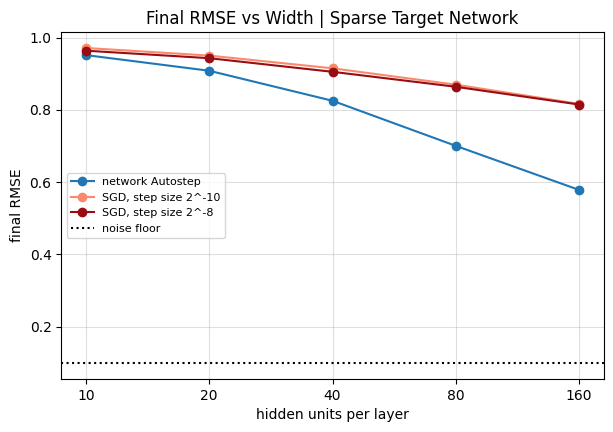

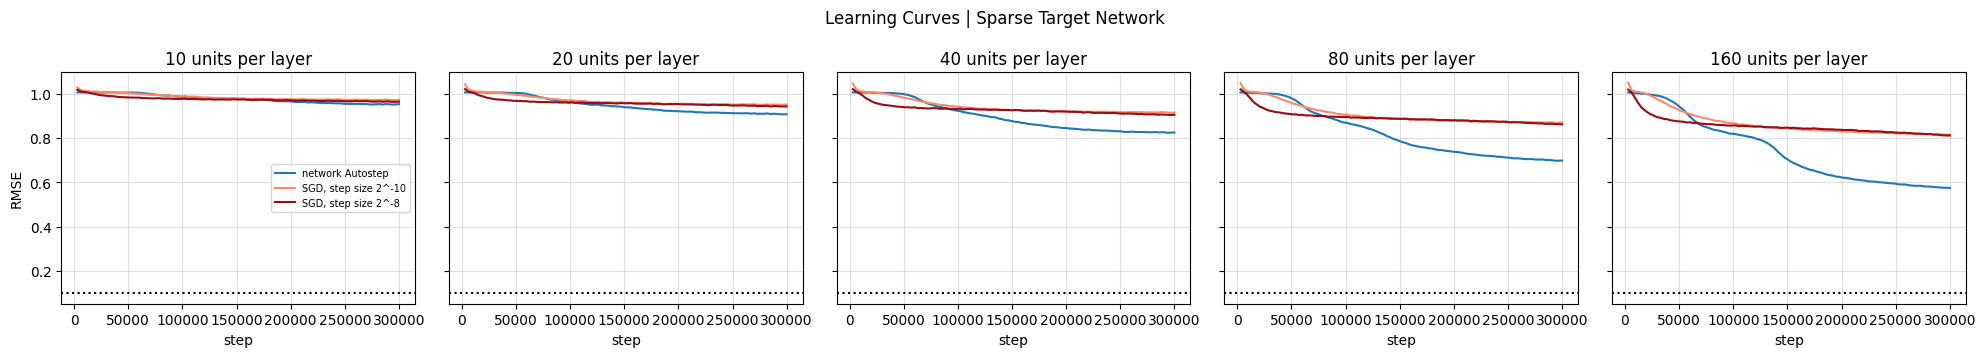

network Autostep         10: 0.951   20: 0.908   40: 0.825   80: 0.700   160: 0.579
SGD, step size 2^-10     10: 0.971   20: 0.950   40: 0.915   80: 0.870   160: 0.816
SGD, step size 2^-8      10: 0.964   20: 0.943   40: 0.905   80: 0.864   160: 0.815


In [7]:
METHODS = ['network Autostep'] + [f'SGD, step size 2^{np.log2(s):.0f}' for s in SGD_STEP_SIZES]
METHOD_COLORS = dict(zip(METHODS, ['tab:blue', *plt.cm.Reds(np.linspace(0.4, 0.9, len(SGD_STEP_SIZES)))]))
WINDOW = NUM_STEPS // N_WINDOWS
STEPS = (np.arange(N_WINDOWS) + 1) * WINDOW
final = lambda rmse: rmse[:, -round(N_WINDOWS * FINAL_FRACTION):].mean()

fig, ax = plt.subplots(figsize=(7, 4.5))
for method in METHODS:
    ax.plot(WIDTHS, [final(scaling[width, method]) for width in WIDTHS], 'o-', color=METHOD_COLORS[method],
            label=method)
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set_xscale('log', base=2)
ax.set_xticks(WIDTHS, [str(w) for w in WIDTHS])
ax.set(xlabel='hidden units per layer', ylabel='final RMSE', title='Final RMSE vs Width | Sparse Target Network')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(1, len(WIDTHS), figsize=(4 * len(WIDTHS), 3.6), sharey=True)
for ax, width in zip(axes, WIDTHS):
    for method in METHODS:
        ax.plot(STEPS, scaling[width, method].mean(0), color=METHOD_COLORS[method], lw=1.5, label=method)
    ax.axhline(NOISE_STD, color='black', ls=':')
    ax.set(xlabel='step', title=f'{width} units per layer')
    ax.grid(alpha=0.4)
axes[0].set_ylabel('RMSE')
axes[0].legend(fontsize=7)
fig.suptitle('Learning Curves | Sparse Target Network')
fig.tight_layout()
plt.show()

for method in METHODS:
    print(f'{method:<24}', '   '.join(f'{w}: {final(scaling[w, method]):.3f}' for w in WIDTHS))

## Unit search

The network has 640 unit slots per depth and starts with no hidden units. Each depth has a budget of 33,280 for its
units' incoming connections and biases, enough for 512 units with 64 inputs; the outputs' connections are not budgeted.
Each hidden unit has room for 128 incoming connections. Every weight but the biases has L1 regularization, its
subgradient added to the gradient Autostep learns from. Every step, a connection is marked for pruning if its weight
crosses zero while its step-size is below half its initial value; biases are never marked. Every $n$ steps, starting
at step 0:
1. *Connection pruning.* The marked connections are pruned, and the marks cleared.
2. *Dead units.* A unit left with no inputs or no outgoing connections is removed.
3. *Unit pruning.* At each depth, the fraction $x$ of its units with the smallest summed |outgoing weight| are pruned,
   with their connections.
4. *Generation.* Depth by depth from depth 1, new units fill the depth's free budget. Each reads 64 sources among the
   inputs and the units of lower depths that existed before this structure change, each picked by choosing a lower
   depth uniformly among those that have units (the inputs are depth 0) and then a unit of that depth. It feeds every
   output; one of these, chosen at random, carries a fixed $\pm 1$ shadow weight: in the backward pass only, it stands
   in for the real weight unless the real one is larger in magnitude or the connection is gone. Below the last depth,
   it also feeds 10 existing units of higher depths, picked the same way, leaving out units with no room left or whose
   depth has no budget left; these connections count against the consumer's depth and are made before that depth's
   new units. Input weights start $U(-10^{-4}, 10^{-4})$, the bias and outgoing weights at 0, and their step-sizes at
   $10^{-4}$.

The first fill, at step 0, makes 512 units per depth, which therefore connect only to the inputs and the outputs.

**Runs.** 300k steps. Unit search, 1 seed per configuration: $n$ = 3k, 10k, 30k and 100k steps, each with $x$ = 3%,
10%, 30% and 50%, each with L1 coefficients 0.001 and 0. *Random sparse* (baseline, 5 seeds, no L1): the first fill,
never changed afterwards. *Target wiring* (reference, 5 seeds): the target network's own
connectivity and depths, learned weights, L1 0.001, no shadow weights. *Fully connected 3 × 160* (reference, 5 seeds):
about 228k connections, close to unit search's roughly 100k budgeted connections plus 150k into the outputs. All use
network Autostep; unit search and random sparse use shadow weights.

In [8]:
class Config(NamedTuple):
    prune_every: int            # steps between structure changes
    prune_fraction: float       # of each depth's units, pruned for low utility at each structure change
    l1: float                   # L1 regularization
    prune_connections: bool     # whether marked connections are pruned


class Search(NamedTuple):
    marked: dict                # connections to prune at the next structure change, shaped like w
    shadow: jax.Array           # shaped like w['output']: the +-1 shadow weight on each unit's paired output, else 0


def empty_network(key):
    # No hidden units yet: only the output biases exist.
    n = N_DEPTHS * SLOTS_PER_DEPTH
    mask = {'hidden': jnp.zeros((n, HIDDEN_CAPACITY + 1), bool),
            'output': jnp.zeros((N_OUTPUTS, n + 1), bool).at[:, -1].set(True)}
    return init_sparse(key, empty_sources(n), mask, jnp.zeros(n, bool))


def teacher_network(key):
    # The target network's own wiring, in blocks of TEACHER_WIDTH slots per depth (its sources are already indexed as
    # inputs, then its hidden units by depth).
    n = N_DEPTHS * TEACHER_WIDTH
    mask = {'hidden': jnp.ones((n, TEACHER_FAN_IN + 1), bool),
            'output': jnp.append(TEACHER['output_w'] != 0, jnp.ones((N_OUTPUTS, 1), bool), axis=1)}
    return init_sparse(key, jax.lax.top_k(TEACHER['hidden_w'] != 0, TEACHER_FAN_IN)[1], mask, jnp.ones(n, bool))


def init_search(net):
    return Search(jax.tree.map(lambda m: jnp.zeros(m.shape, bool), net.mask), jnp.zeros(net.w['output'].shape))


def shadow_feedback(net, search):
    # The output weights the backward pass uses: each unit's paired output weight is replaced by its shadow weight
    # unless the real one is larger in magnitude.
    w = net.w['output']
    return jnp.where((search.shadow != 0) & (jnp.abs(w) < 1.0), search.shadow, w) * net.mask['output']


def gumbel_top(key, p, k):
    # k distinct indices drawn without replacement in proportion to p (Gumbel top-k), and whether each is valid (fewer
    # than k entries of p may be positive).
    scores = jnp.where(p > 0, jnp.log(jnp.maximum(p, 1e-30)) + jax.random.gumbel(key, p.shape), -jnp.inf)
    values, indices = jax.lax.top_k(scores, k)
    return indices, values > -jnp.inf


def layer_uniform(node_depth):
    # Each node's probability when a depth is chosen uniformly among the depths that have nodes (node_depth >= 0),
    # and then a node of that depth.
    count = jnp.zeros(N_DEPTHS + 2).at[jnp.maximum(node_depth, 0)].add(node_depth >= 0)
    share = jnp.where(count > 0, 1.0 / jnp.maximum((count > 0).sum(), 1), 0.0) / jnp.maximum(count, 1)
    return jnp.where(node_depth >= 0, share[jnp.maximum(node_depth, 0)], 0.0)


def per_unit(net, mask, value):
    # Each slot's sum of `value` (shaped like net.w) over its outgoing connections, those that `mask` keeps.
    n = len(net.alive)
    read = net.src - N_INPUTS
    reads = mask['hidden'][:, :-1] & (read >= 0) & (read < n)
    hidden = jnp.zeros(n + 1).at[jnp.where(reads, read, n)].add(jnp.where(reads, value['hidden'][:, :-1], 0.0))
    return hidden[:n] + jnp.sum(jnp.where(mask['output'], value['output'], 0.0), axis=0)[:n]


def restructure(net, search, config, key):
    # A structure change. Returns the new network and search state, the number of units removed, and the number of
    # connections cut by connection pruning.
    n, block = len(net.alive), SLOTS_PER_DEPTH
    slot_depth = jnp.arange(n) // block + 1
    empty = empty_sources(n)                                      # the sources of empty connection slots
    w, mask, src, alive = dict(net.w), dict(net.mask), net.src, net.alive
    read = src - N_INPUTS                                         # the slot a connection reads, if any
    ones = jax.tree.map(lambda m: jnp.ones(m.shape), mask)

    # 1. Marked connections are pruned (biases are never marked).
    cut = {k: search.marked[k] & mask[k] & config.prune_connections for k in mask}
    kept = {k: mask[k] & ~cut[k] for k in mask}

    # 2. Units left with no inputs or no outgoing connections are removed. 3. At each depth, the prune fraction of its
    # units with the smallest summed |outgoing weight| are pruned. A removed unit's connections go with it.
    dead = alive & ((kept['hidden'][:, :-1].sum(1) == 0) | (per_unit(net, kept, ones) == 0))
    utility = per_unit(net, kept, jax.tree.map(jnp.abs, w))
    eligible = alive & ~dead
    removed = dead
    for d in range(N_DEPTHS):
        rows = slice(d * block, (d + 1) * block)
        rank = jnp.argsort(jnp.argsort(jnp.where(eligible[rows], utility[rows], jnp.inf)))
        pruned = eligible[rows] & (rank < jnp.floor(config.prune_fraction * alive[rows].sum()))
        removed = removed.at[rows].set(removed[rows] | pruned)
    reads_removed = (read >= 0) & (read < n) & removed[jnp.clip(read, 0, n - 1)]
    gone = {'hidden': cut['hidden'] | jnp.append(reads_removed, jnp.zeros((n, 1), bool), axis=1) | removed[:, None],
            'output': cut['output'] | jnp.append(removed, False)[None]}
    mask = {k: mask[k] & ~gone[k] for k in mask}
    src = jnp.where(gone['hidden'][:, :-1], empty, src)
    shadow = jnp.where(gone['output'], 0.0, search.shadow)
    alive = alive & ~removed

    # 4. Generation, depth by depth from depth 1. New units fill the depth's free budget (its units' incoming
    # connections and biases), as far as its free slots allow. Each reads FAN_IN sources among the inputs and the
    # existing units of lower depths, each picked by choosing a lower depth uniformly among those that have units and
    # then a unit of that depth; feeds every output, one of them, chosen at random, carrying a fixed +-1 shadow weight;
    # and, below the last depth, feeds FAN_OUT existing units of higher depths, picked the same way, leaving out units
    # with no free connection slot or whose depth has no budget left. These count against the consumer's depth, before
    # that depth's new units are made. Existing units: those from before this structure change. Input weights start U(-INIT_STEP_SIZE, INIT_STEP_SIZE), the bias and outgoing weights at 0, their
    # step-sizes at INIT_STEP_SIZE with Autostep's traces at 0, and the unit's statistics as at the start.
    existing = alive
    new_all = jnp.zeros(n, bool)
    changed = {'hidden': jnp.zeros(mask['hidden'].shape, bool), 'output': jnp.zeros(mask['output'].shape, bool)}
    for d, depth_key in enumerate(jax.random.split(key, N_DEPTHS)):
        rows = slice(d * block, (d + 1) * block)
        source_key, consumer_key, pair_key, sign_key, weight_key = jax.random.split(depth_key, 5)
        free_slots = ~alive[rows]
        count = jnp.minimum((DEPTH_BUDGET - mask['hidden'][rows].sum()) // UNIT_COST, free_slots.sum())
        new = free_slots & (jnp.cumsum(free_slots) <= count)
        slot = jnp.arange(block) + d * block

        node_depth = jnp.concatenate([jnp.zeros(N_INPUTS, int), jnp.where(existing, slot_depth, -1)])
        p = layer_uniform(jnp.where(node_depth <= d, node_depth, -1))
        source, source_ok = jax.vmap(lambda k: gumbel_top(k, p, FAN_IN))(jax.random.split(source_key, block))
        row_src = empty[rows].at[:, :FAN_IN].set(jnp.where(source_ok, source, empty[rows, :FAN_IN]))
        row_mask = jnp.zeros((block, HIDDEN_CAPACITY + 1), bool).at[:, :FAN_IN].set(source_ok).at[:, -1].set(True)
        row_w = jax.random.uniform(weight_key, row_mask.shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE)
        src = src.at[rows].set(jnp.where(new[:, None], row_src, src[rows]))
        mask['hidden'] = mask['hidden'].at[rows].set(jnp.where(new[:, None], row_mask, mask['hidden'][rows]))
        w['hidden'] = w['hidden'].at[rows].set(jnp.where(new[:, None], (row_w * row_mask).at[:, -1].set(0.0),
                                                         w['hidden'][rows]))
        changed['hidden'] = changed['hidden'].at[rows].set(changed['hidden'][rows] | new[:, None])

        column = jnp.append(jnp.zeros(n, bool).at[rows].set(new), False)[None]
        mask['output'], changed['output'] = mask['output'] | column, changed['output'] | column
        w['output'] = jnp.where(column, 0.0, w['output'])
        paired = jnp.arange(N_OUTPUTS)[:, None] == jax.random.randint(pair_key, (block,), 0, N_OUTPUTS)[None]
        sign = jax.random.rademacher(sign_key, (block,), dtype=jnp.float32)
        shadow = shadow.at[:, rows].set(jnp.where(new[None], paired * sign[None], shadow[:, rows]))

        if d < N_DEPTHS - 1:
            # Each new unit's connection into each of its consumers goes in that consumer's next free slot; a consumer
            # fed by more new units than it has free slots keeps only the first ones, and so does a depth fed more
            # connections than it has budget left.
            room = DEPTH_BUDGET - jnp.zeros(N_DEPTHS + 1).at[slot_depth].add(mask['hidden'].sum(1))
            free = HIDDEN_CAPACITY - mask['hidden'][:, :-1].sum(1)
            open_unit = existing & (slot_depth > d + 1) & (free > 0) & (room[slot_depth] > 0)
            q = layer_uniform(jnp.where(open_unit, slot_depth, -1))
            consumer, consumer_ok = jax.vmap(lambda k: gumbel_top(k, q, FAN_OUT))(jax.random.split(consumer_key, block))
            feeds = jnp.zeros((block, n), bool).at[jnp.arange(block)[:, None], consumer].set(consumer_ok & new[:, None])
            order = jnp.cumsum(feeds, axis=0) - 1                 # among the new units feeding the same consumer
            feeds = feeds & (order < free[None])
            for e in range(d + 2, N_DEPTHS + 1):
                into = feeds & (slot_depth == e)[None]
                feeds = feeds & ~(into & (jnp.cumsum(into.reshape(-1)).reshape(into.shape) > room[e]))
            open_slots = jnp.argsort(mask['hidden'][:, :-1], axis=1, stable=True)    # each unit's empty slots first
            row = jnp.where(feeds, jnp.arange(n)[None], n)                           # out of range: dropped
            col = open_slots[jnp.arange(n)[None], jnp.clip(order, 0, HIDDEN_CAPACITY - 1)]
            src = src.at[row, col].set(jnp.broadcast_to(N_INPUTS + slot[:, None], row.shape), mode='drop')
            mask['hidden'] = mask['hidden'].at[row, col].set(True, mode='drop')
            w['hidden'] = w['hidden'].at[row, col].set(0.0, mode='drop')
            changed['hidden'] = changed['hidden'].at[row, col].set(True, mode='drop')

        alive = alive.at[rows].set(alive[rows] | new)
        new_all = new_all.at[rows].set(new)

    opt = net.opt
    reset = lambda tree, value: {k: jnp.where(changed[k], value, tree[k]) for k in tree}
    net = net._replace(
        w=w, mask=mask, src=src, alive=alive,
        opt=opt._replace(beta=reset(opt.beta, jnp.log(INIT_STEP_SIZE)), h=reset(opt.h, 0.0), v=reset(opt.v, 0.0)),
        stats=Stats(*(jnp.where(new_all, value, s) for s, value in zip(net.stats, (0.5, 0.0, 0.0)))))
    search = Search(jax.tree.map(jnp.zeros_like, search.marked), shadow)
    return net, search, removed.sum(), sum(c.sum() for c in cut.values())

In [9]:
def train_search(net, search, key, config, num_steps, fixed):
    # num_steps online network-Autostep steps. Every BASE_PERIOD steps comes a structure change if one is due (every
    # prune_every steps from step 0, whose structure change is the first fill), unless the network is fixed, which also
    # has no shadow weights. Every step, connections whose weight crosses zero while their step-size is below half its
    # initial value are marked for pruning. Returns every recorded value averaged over each window.
    def one_step(carry, key):
        net, search = carry
        new, mse = learn_sparse(net, *next_sample(key), None if fixed else shadow_feedback(net, search), config.l1)
        if not fixed:
            search = search._replace(marked={
                k: search.marked[k] | ((net.w[k] * new.w[k] < 0) & (jnp.exp(new.opt.beta[k]) < INIT_STEP_SIZE / 2)
                                       & net.mask[k]).at[:, -1].set(False) for k in new.w})
        return (new, search), mse

    def period(carry, inputs):
        step, key = inputs
        restructure_key, step_key = jax.random.split(key)
        units_before = carry[0].alive.sum()
        removed = cut = 0
        if not fixed:
            changed = restructure(*carry, config, restructure_key)
            due = step % config.prune_every == 0
            *carry, removed, cut = jax.tree.map(lambda a, b: jnp.where(due, a, b), changed, (*carry, 0, 0))
        (net, search), mse = jax.lax.scan(one_step, tuple(carry), jax.random.split(step_key, BASE_PERIOD))
        units = net.alive.reshape(N_DEPTHS, -1).sum(1)
        record = {'mse': mse.mean(), 'units': units.sum(), 'removed': removed / BASE_PERIOD,
                  'cut per unit': cut / jnp.maximum(units_before, 1) / BASE_PERIOD,
                  'budgeted connections': net.mask['hidden'].sum(),
                  **{f'depth {d + 1}': units[d] for d in range(N_DEPTHS)}}
        return (net, search), jax.tree.map(lambda v: jnp.asarray(v, jnp.float32), record)

    periods = num_steps // N_WINDOWS // BASE_PERIOD

    def window(carry, inputs):
        index, key = inputs
        steps = (index * periods + jnp.arange(periods)) * BASE_PERIOD
        carry, records = jax.lax.scan(period, carry, (steps, jax.random.split(key, periods)))
        return carry, jax.tree.map(lambda r: r.mean(0), records)

    return jax.lax.scan(window, (net, search), (jnp.arange(N_WINDOWS), jax.random.split(key, N_WINDOWS)))[1]


def run_search(make_network, configs, seeds, num_steps, fixed=False):
    # Each config on its seed (lists of the same length), vmapped in batches of RUNS_PER_BATCH; `make_network(key)`
    # makes the starting network. Seed s gives every run the same initial network and samples. Returns records shaped
    # (run, window), with 'rmse'.
    keys = lambda seed: jax.random.split(jax.random.PRNGKey(seed), N_SEEDS)[jnp.array(seeds)]
    nets = jax.vmap(make_network)(keys(0))
    runs = (nets, jax.vmap(init_search)(nets), keys(1), jax.tree.map(lambda *values: jnp.array(values), *configs))
    train = jax.jit(jax.vmap(lambda net, s, k, c: train_search(net, s, k, c, num_steps, fixed)))
    started = perf_counter()
    batches = [jax.tree.map(np.asarray, train(*jax.tree.map(lambda a: a[i:i + RUNS_PER_BATCH], runs)))
               for i in range(0, len(configs), RUNS_PER_BATCH)]
    records = jax.tree.map(lambda *r: np.concatenate(r), *batches)
    records['rmse'] = np.sqrt(records['mse'])
    print(f'{len(configs)} runs in {perf_counter() - started:.0f}s')
    return records

In [10]:
SEARCH_CONFIGS = [Config(every, fraction, l1, True) for l1 in L1S for every in PRUNE_EVERY for fraction in PRUNE_FRACTIONS]
RANDOM_SPARSE = [Config(SEARCH_STEPS, 0.0, 0.0, False)] * N_SEEDS
records = run_search(empty_network, SEARCH_CONFIGS + RANDOM_SPARSE, [0] * len(SEARCH_CONFIGS) + list(range(N_SEEDS)),
                     SEARCH_STEPS)
searches = {config: {k: v[i:i + 1] for k, v in records.items()} for i, config in enumerate(SEARCH_CONFIGS)}
references = {
    'random sparse (baseline)': {k: v[len(SEARCH_CONFIGS):] for k, v in records.items()},
    'target wiring (reference)': run_search(teacher_network, [Config(SEARCH_STEPS, 0.0, L1S[0], False)] * N_SEEDS,
                                            list(range(N_SEEDS)), SEARCH_STEPS, fixed=True),
    f'fully connected, 3 x {WIDTHS[-1]} (reference)': {'rmse': run_dense(WIDTHS[-1], True, [0.0], SEARCH_STEPS)[0]}}

2026-10-29 22:07:01.561305: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 22:07:01.561360: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 22:07:01.561375: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


37 runs in 789s


5 runs in 21s


5 runs in 22s


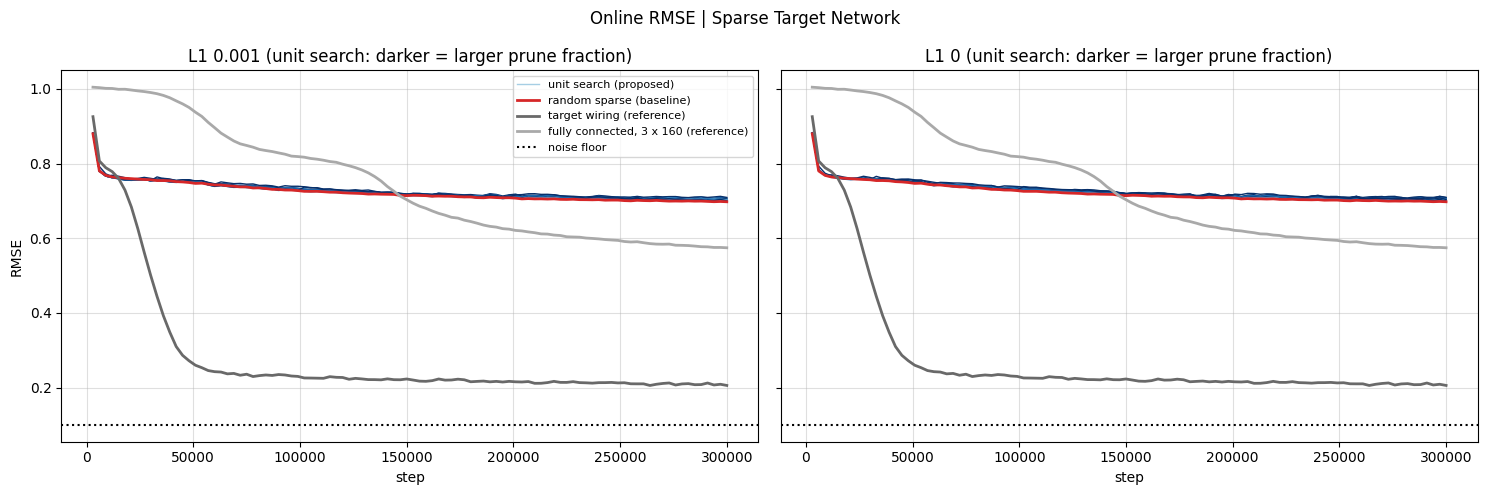

random sparse (baseline)                      0.699
target wiring (reference)                     0.209
fully connected, 3 x 160 (reference)          0.579
unit search, L1 0.001; rows: steps between structure changes; columns: prune fractions 0.03, 0.1, 0.3, 0.5
     3000: 0.705  0.708  0.709  0.710
    10000: 0.703  0.705  0.705  0.705
    30000: 0.704  0.705  0.705  0.703
   100000: 0.702  0.702  0.703  0.702
unit search, L1 0; rows: steps between structure changes; columns: prune fractions 0.03, 0.1, 0.3, 0.5
     3000: 0.705  0.707  0.707  0.710
    10000: 0.703  0.706  0.708  0.709
    30000: 0.701  0.704  0.706  0.706
   100000: 0.702  0.701  0.702  0.703


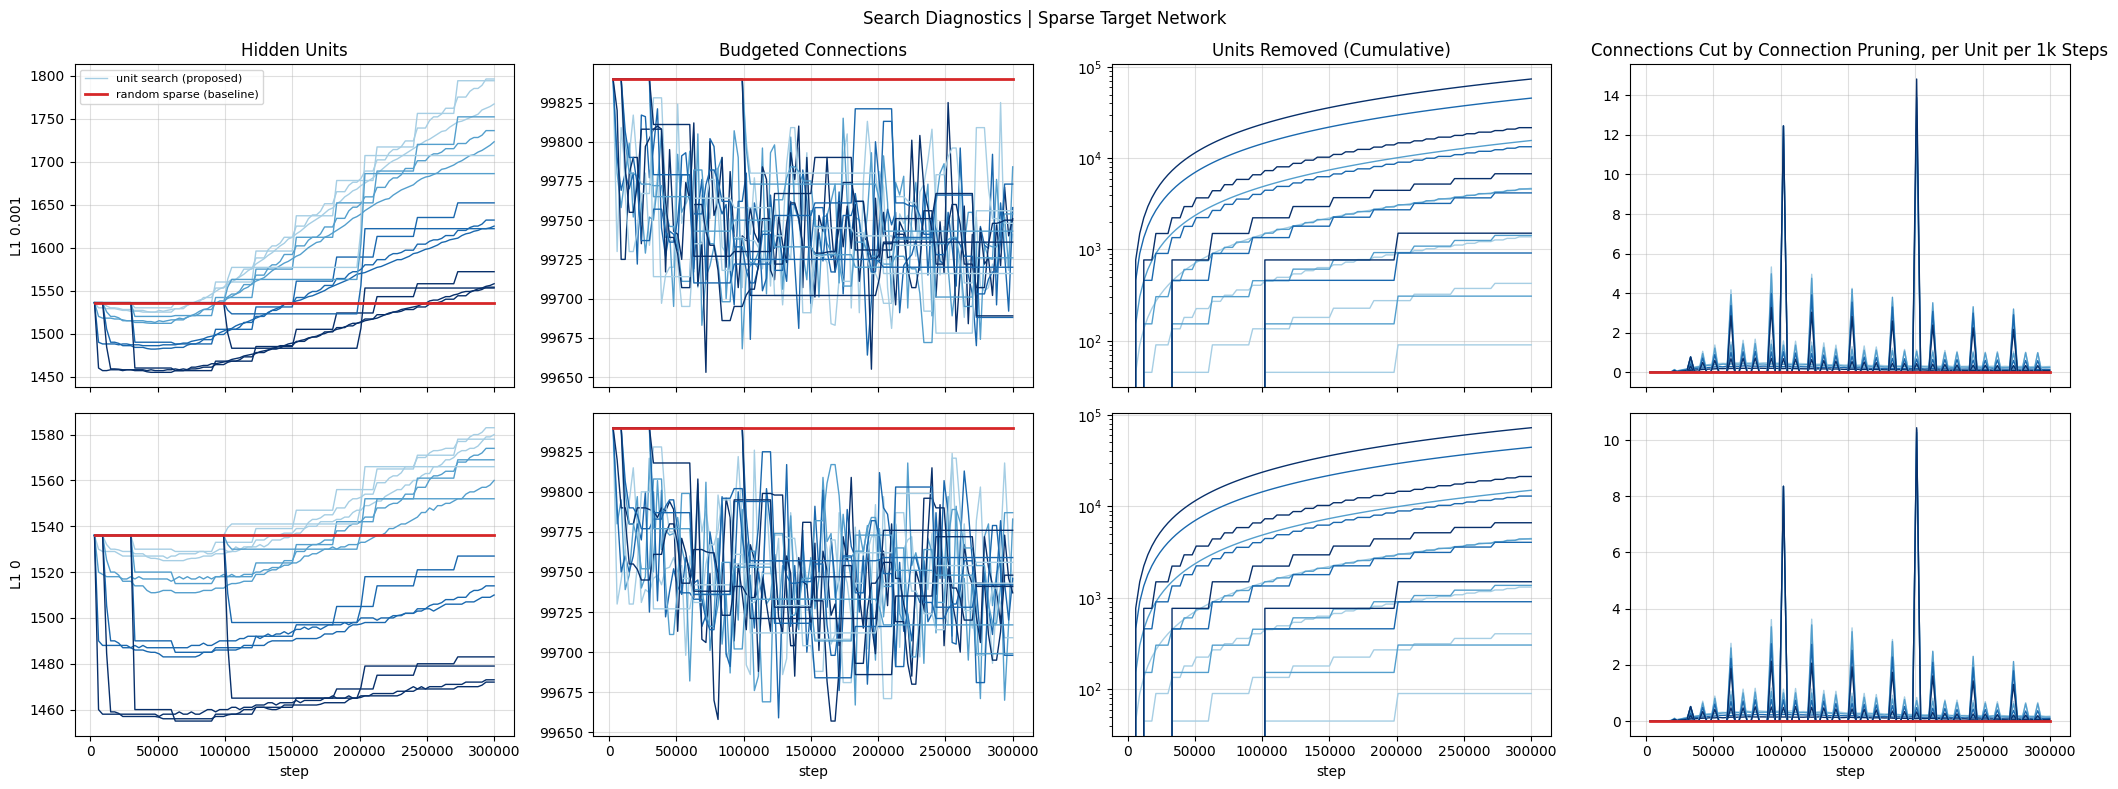

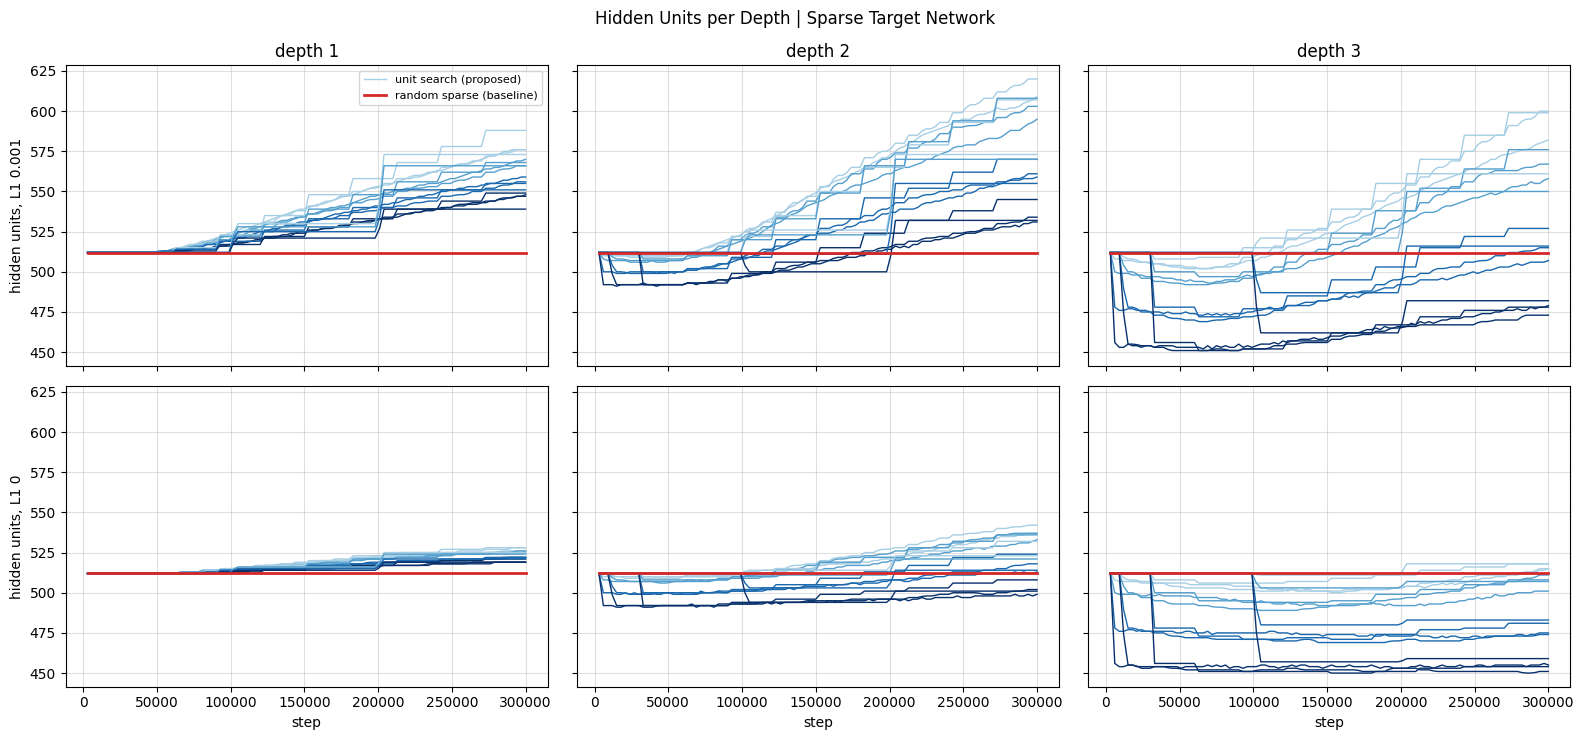

In [11]:
SEARCH_X = (np.arange(N_WINDOWS) + 1) * (SEARCH_STEPS // N_WINDOWS)
FRACTION_COLORS = dict(zip(PRUNE_FRACTIONS, plt.cm.Blues(np.linspace(0.35, 1.0, len(PRUNE_FRACTIONS)))))
OTHER_REFERENCES = {'target wiring (reference)': 'dimgray', f'fully connected, 3 x {WIDTHS[-1]} (reference)': 'darkgray'}


def curves(l1, with_references=False):
    # (label, records, style) of each curve in the panels for one L1 coefficient: the unit search runs, labeled once
    # and colored by prune fraction; random sparse; and with_references, the other references.
    runs = [c for c in SEARCH_CONFIGS if c.l1 == l1]
    out = [('unit search (proposed)' if i == 0 else None, searches[c], dict(color=FRACTION_COLORS[c.prune_fraction],
                                                                            lw=1)) for i, c in enumerate(runs)]
    out.append(('random sparse (baseline)', references['random sparse (baseline)'], dict(color='tab:red', lw=2)))
    if with_references:
        out += [(label, references[label], dict(color=color, lw=2)) for label, color in OTHER_REFERENCES.items()]
    return out


fig, axes = plt.subplots(1, len(L1S), figsize=(15, 5), sharey=True)
for ax, l1 in zip(axes, L1S):
    for label, res, style in curves(l1, with_references=True):
        ax.plot(SEARCH_X, res['rmse'].mean(0), label=label, **style)
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step', title=f'L1 {l1:g} (unit search: darker = larger prune fraction)')
    ax.grid(alpha=0.4)
axes[0].set_ylabel('RMSE')
axes[0].legend(fontsize=8)
fig.suptitle('Online RMSE | Sparse Target Network')
fig.tight_layout()
plt.show()

for label, res in references.items():
    print(f'{label:<45} {final(res["rmse"]):.3f}')
for l1 in L1S:
    print(f'unit search, L1 {l1:g}; rows: steps between structure changes; columns: prune fractions',
          ', '.join(f'{x:g}' for x in PRUNE_FRACTIONS))
    for every in PRUNE_EVERY:
        print(f'  {every:>7}:', '  '.join(f'{final(searches[Config(every, x, l1, True)]["rmse"]):.3f}'
                                         for x in PRUNE_FRACTIONS))

fig, axes = plt.subplots(len(L1S), 4, figsize=(21, 8), sharex=True)
for row, l1 in zip(axes, L1S):
    for label, res, style in curves(l1):
        row[0].plot(SEARCH_X, res['units'].mean(0), label=label, **style)
        row[1].plot(SEARCH_X, res['budgeted connections'].mean(0), **style)
        row[2].plot(SEARCH_X, np.cumsum(res['removed'].mean(0) * (SEARCH_STEPS // N_WINDOWS)), **style)
        row[3].plot(SEARCH_X, 1000 * res['cut per unit'].mean(0), **style)
    row[0].set_ylabel(f'L1 {l1:g}')
    row[2].set_yscale('log')
    for ax in row:
        ax.grid(alpha=0.4)
for ax, title in zip(axes[0], ['Hidden Units', 'Budgeted Connections', 'Units Removed (Cumulative)',
                               'Connections Cut by Connection Pruning, per Unit per 1k Steps']):
    ax.set_title(title)
for ax in axes[-1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Search Diagnostics | Sparse Target Network')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(len(L1S), N_DEPTHS, figsize=(16, 7.5), sharex=True, sharey=True)
for row, l1 in zip(axes, L1S):
    for d, ax in zip(range(1, N_DEPTHS + 1), row):
        for label, res, style in curves(l1):
            ax.plot(SEARCH_X, res[f'depth {d}'].mean(0), label=label, **style)
        ax.grid(alpha=0.4)
    row[0].set_ylabel(f'hidden units, L1 {l1:g}')
for d, ax in zip(range(1, N_DEPTHS + 1), axes[0]):
    ax.set_title(f'depth {d}')
for ax in axes[-1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Hidden Units per Depth | Sparse Target Network')
fig.tight_layout()
plt.show()

## Results

300k steps, RMSE over the last 10% of training; unit search has 1 seed per configuration, everything else 5.
Connections: unit search and random sparse about 100k budgeted plus about 150k into the outputs; target wiring 1,660;
fully connected 11,230 (10 units per layer) to 227,680 (160). The unit search grid takes about 13 minutes.

- **Fixed connectivity.** Every width ends far from the noise floor (0.1). Network Autostep scales best, from 0.95 at
  10 units per layer to 0.58 at 160; SGD's best step size reaches 0.82.
- **Unit search does not beat random sparse.** Every configuration ends between 0.70 and 0.71, against 0.70 for
  random sparse; pruning more units, or more often, is slightly worse. The target network's own wiring reaches 0.21.
- **Random sparse learns fast, then stalls.** It reaches 0.76 within 10k steps and then improves slowly; the fully
  connected 3 × 160 network passes it at about 150k steps.
- **Structure.** Units outgrow the first 512 per depth as connection pruning and removed sources shrink their inputs,
  to about 600 per depth with L1. Connection pruning cuts more with L1 than without.